In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import math

In [2]:
df = pd.read_csv("training.csv")

In [3]:
df.shape

(4600, 18)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float64(4), int6

In [5]:
print(df.duplicated().sum())

0


In [6]:
print((df.select_dtypes('number') == 0).sum())

price              49
bedrooms            2
bathrooms           2
sqft_living         0
sqft_lot            0
floors              0
waterfront       4567
view             4140
condition           0
sqft_above          0
sqft_basement    2745
yr_built            0
yr_renovated     2735
dtype: int64


In [7]:
df = df.loc[(df["price"]>0) & (df["bedrooms"]>0) & (df["bathrooms"]>0)]

In [8]:
len(df)

4549

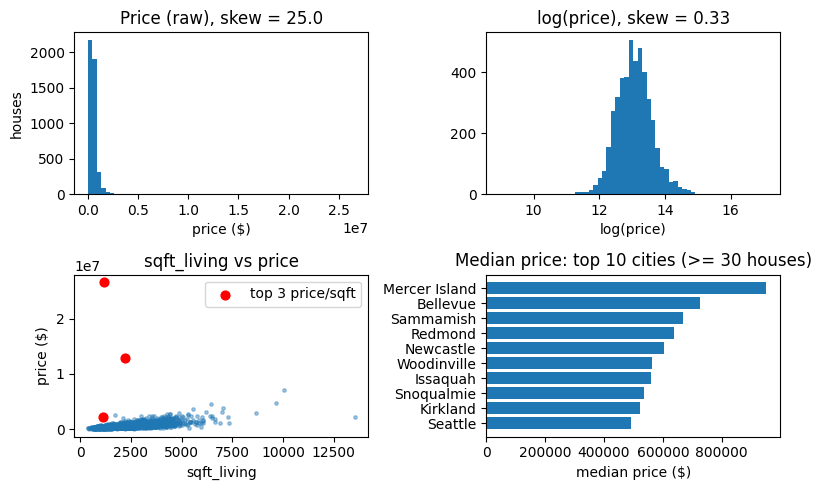

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(8, 5))

# 1) price: raw vs log
ax[0, 0].hist(df.price, bins=60)
ax[0, 0].set_title(f"Price (raw), skew = {df.price.skew():.1f}")
ax[0, 0].set_xlabel("price ($)"); ax[0, 0].set_ylabel("houses")

ax[0, 1].hist(np.log(df.price), bins=60)
ax[0, 1].set_title(f"log(price), skew = {np.log(df.price).skew():.2f}")
ax[0, 1].set_xlabel("log(price)")

# 2) sqft_living vs price (top 3 price/sqft in red)
ppsf = df.price / df.sqft_living
top = df.loc[ppsf.nlargest(3).index]
ax[1, 0].scatter(df.sqft_living, df.price, s=6, alpha=0.4)
ax[1, 0].scatter(top.sqft_living, top.price, s=40, color="red", label="top 3 price/sqft")
ax[1, 0].set_title("sqft_living vs price")
ax[1, 0].set_xlabel("sqft_living"); ax[1, 0].set_ylabel("price ($)"); ax[1, 0].legend()

# 3) median price: top 10 cities (min 30 houses)
g = df.groupby("city").price.agg(["median", "count"])
g = g[g["count"] >= 30].sort_values("median", ascending=False).head(10)
ax[1, 1].barh(g.index[::-1], g["median"][::-1])
ax[1, 1].set_title("Median price: top 10 cities (>= 30 houses)")
ax[1, 1].set_xlabel("median price ($)")

plt.tight_layout()
plt.show()

#### Outlier removal

In [10]:
df['price_per_sqft'] = df['price']/df['sqft_living'] # Make new column

In [11]:
# Finding the 99.5th percentile
threshold = df["price_per_sqft"].quantile(0.995)

In [12]:
print(threshold) # $675 per sqft

675.1262903020267


In [13]:
df = df.loc[df['price_per_sqft'] <= threshold]

In [14]:
len(df)

4526

In [15]:
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country,price_per_sqft
0,2014-05-02 00:00:00,3.130000e+05,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA,233.582090
1,2014-05-02 00:00:00,2.384000e+06,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA,653.150685
2,2014-05-02 00:00:00,3.420000e+05,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA,177.202073
3,2014-05-02 00:00:00,4.200000e+05,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA,210.000000
4,2014-05-02 00:00:00,5.500000e+05,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA,283.505155
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,2014-07-09 00:00:00,3.081667e+05,3.0,1.75,1510,6360,1.0,0,0,4,1510,0,1954,1979,501 N 143rd St,Seattle,WA 98133,USA,204.083885
4596,2014-07-09 00:00:00,5.343333e+05,3.0,2.50,1460,7573,2.0,0,0,3,1460,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,USA,365.981735
4597,2014-07-09 00:00:00,4.169042e+05,3.0,2.50,3010,7014,2.0,0,0,3,3010,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,USA,138.506368
4598,2014-07-10 00:00:00,2.034000e+05,4.0,2.00,2090,6630,1.0,0,0,3,1070,1020,1974,0,5148 S Creston St,Seattle,WA 98178,USA,97.320574


#### Feature Engineering

In [16]:
# After seeing dataset carefully- sqft_living = sqft_above + sqft_basement, let's verify

(df["sqft_living"] == df["sqft_above"] + df["sqft_basement"]).all() # It means either of sqft_above or sqft_base is redundant. Because it can be cacl.

np.True_

In [17]:
# Feature 1: renovated
df['renovated'] = (df['yr_renovated'] > 0).astype(int) 

In [18]:
# Feature 2: age
df['age'] = 2014 - df['yr_built'] # Dataset is of 2014 

In [19]:
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_basement,yr_built,yr_renovated,street,city,statezip,country,price_per_sqft,renovated,age
0,2014-05-02 00:00:00,3.130000e+05,3.0,1.50,1340,7912,1.5,0,0,3,...,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA,233.582090,1,59
1,2014-05-02 00:00:00,2.384000e+06,5.0,2.50,3650,9050,2.0,0,4,5,...,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA,653.150685,0,93
2,2014-05-02 00:00:00,3.420000e+05,3.0,2.00,1930,11947,1.0,0,0,4,...,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA,177.202073,0,48
3,2014-05-02 00:00:00,4.200000e+05,3.0,2.25,2000,8030,1.0,0,0,4,...,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA,210.000000,0,51
4,2014-05-02 00:00:00,5.500000e+05,4.0,2.50,1940,10500,1.0,0,0,4,...,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA,283.505155,1,38
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,2014-07-09 00:00:00,3.081667e+05,3.0,1.75,1510,6360,1.0,0,0,4,...,0,1954,1979,501 N 143rd St,Seattle,WA 98133,USA,204.083885,1,60
4596,2014-07-09 00:00:00,5.343333e+05,3.0,2.50,1460,7573,2.0,0,0,3,...,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,USA,365.981735,1,31
4597,2014-07-09 00:00:00,4.169042e+05,3.0,2.50,3010,7014,2.0,0,0,3,...,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,USA,138.506368,0,5
4598,2014-07-10 00:00:00,2.034000e+05,4.0,2.00,2090,6630,1.0,0,0,3,...,1020,1974,0,5148 S Creston St,Seattle,WA 98178,USA,97.320574,0,40


In [20]:
# Now drop useless columns
df = df.drop(columns = ['date','street','statezip','country','yr_built','yr_renovated','sqft_above','price_per_sqft']) # price_per_sqft is for only outlier detection.

In [21]:
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_basement,city,renovated,age
0,3.130000e+05,3.0,1.50,1340,7912,1.5,0,0,3,0,Shoreline,1,59
1,2.384000e+06,5.0,2.50,3650,9050,2.0,0,4,5,280,Seattle,0,93
2,3.420000e+05,3.0,2.00,1930,11947,1.0,0,0,4,0,Kent,0,48
3,4.200000e+05,3.0,2.25,2000,8030,1.0,0,0,4,1000,Bellevue,0,51
4,5.500000e+05,4.0,2.50,1940,10500,1.0,0,0,4,800,Redmond,1,38
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,3.081667e+05,3.0,1.75,1510,6360,1.0,0,0,4,0,Seattle,1,60
4596,5.343333e+05,3.0,2.50,1460,7573,2.0,0,0,3,0,Bellevue,1,31
4597,4.169042e+05,3.0,2.50,3010,7014,2.0,0,0,3,0,Renton,0,5
4598,2.034000e+05,4.0,2.00,2090,6630,1.0,0,0,3,1020,Seattle,0,40


In [22]:
# One-Hot Encoding of cities
df = pd.get_dummies(df, columns = ['city']) # It makes new columns of every city and convert into 0s and 1s for each house whether it belongs to that city or not

In [23]:
df.shape

(4526, 56)

#### Split + Scaling

In [24]:
y = np.log(df['price'])
X = df.drop(columns = ['price'])

In [25]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4526, 55)
y shape: (4526,)


In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42) # random_state ensures data is split into the exact same training and testing sets every time.
print(X_train.shape, X_test.shape)

(3620, 55) (906, 55)


In [27]:
# Baseline RMSE on test dataset
baseline_prediction = np.mean(y_train) # The value of b in y = w*X+b as w = 0
Baseline_RMSE = np.sqrt(np.mean((baseline_prediction - y_test)**2))

In [28]:
print(f"Baseline_RMSE_test = {Baseline_RMSE}")
print(f"MSE without any features = {baseline_prediction}")

Baseline_RMSE_test = 0.5157928647257931
MSE without any features = 13.055527877144986


#### Z-score Normalization

In [29]:
mu = X_train.mean(axis=0).to_numpy()     # Every feature's mean, n-sized
sigma = X_train.std(axis=0).to_numpy()   # Every feature's std. deviation

Remember- We have done feature engineering. There might be house that belongs to a particular city but is not present in training set. So sigma value for those is 0(as whole column value is 0) and (X - mu) / sigma will be divide by zero which is a error.

Fix- Whereever there's 0 in sigma mark it as 1

In [30]:
X_train = X_train.to_numpy() # m,n sized array 
X_test = X_test.to_numpy()
sigma = np.where(sigma == 0, 1, sigma)

In [31]:
X_train_norm = (X_train - mu) / sigma # m,n sized array 
X_test_norm  = (X_test  - mu) / sigma # SAME mu, sigma (Of train ones!)

In [32]:
# Because before this they are of obj type as X_train contains mix of dtypes like int,float,bool
X_train_norm = X_train_norm.astype(float)
X_test_norm = X_test_norm.astype(float)

#### Sklearn Ablation Study

In [33]:
# Model- A(When first 8 features are taken)
X_train_A = X_train_norm[:, 0:8] # m, 8 sized
X_test_A = X_test_norm[:, 0:8]

In [34]:
model_A = LinearRegression()
c = model_A.fit(X_train_A, y_train)

In [35]:
preds_A = model_A.predict(X_test_A)

In [36]:
rmse_A = np.sqrt(mean_squared_error(y_test, preds_A))
print(f"RMSE of Model A: {rmse_A}")

RMSE of Model A: 0.3659210868148313


In [37]:
r2_A = r2_score(y_test, preds_A)  
print(f"R^2 of Model A: {r2_A}")

R^2 of Model A: 0.4964483931528868


In [38]:
# Model B- When 8 + 3(sqft_basement, renovated, age) are taken
X_train_B = X_train_norm[:, 0:11]
X_test_B  = X_test_norm[:, 0:11]

model_B = LinearRegression()
c = model_B.fit(X_train_B, y_train)

In [39]:
preds_B = model_B.predict(X_test_B)

In [40]:
rmse_B = np.sqrt(mean_squared_error(y_test, preds_B))
print(f"RMSE of Model B: {rmse_B}")

RMSE of Model B: 0.3546569131162393


In [41]:
r2_B = r2_score(y_test, preds_B)  
print(f"R^2 of Model B: {r2_B}")

R^2 of Model B: 0.5269729557337692


In [42]:
# Model C- When 8+3+44(One-hot columns taken)= Whole array
X_train_C = X_train_norm
X_test_C  = X_test_norm

model_C = LinearRegression()
c = model_C.fit(X_train_C, y_train)

In [43]:
preds_C = model_C.predict(X_test_C) # Shape = 906 i.e. no. of egs. in test set

In [44]:
rmse_C = np.sqrt(mean_squared_error(y_test, preds_C))
print(f"RMSE of Model C: {rmse_C}")

RMSE of Model C: 0.27208370617167843


In [45]:
r2_C = r2_score(y_test, preds_C)  
print(f"R^2 of Model C: {r2_C}")

R^2 of Model C: 0.7215968266642282


#### Vectorized cost fxn aur compute gradient

In [46]:
print(y_train)

954     13.054085
3717    12.703661
253     12.948010
1521    12.802158
4560    11.792449
          ...    
4476    13.608056
469     13.644129
3106    13.235692
3790    13.132314
865     12.733755
Name: price, Length: 3620, dtype: float64


In [47]:
# Cost fxn
# def cost_fxn(X,y,w,b):
#     m,n = X.shape
#     f_wb = np.dot(X, w) + b # Shape: (m,) 
#     J_wb = 0
#     y = y.to_numpy() 
#     err = f_wb - y
#     for i in range(m): # For this to execute y_train should be in numpy_arr. If not then key error will be there
#         J_wb += err[i] ** 2
#     J_wb = J_wb / (2 * m)         # Scale by 1/(2m)
#     return J_wb

In [48]:
def cost_fxn(X,y,w,b):
    m,n = X.shape
    f_wb = np.dot(X, w) + b # Shape: (m,) 
    err = f_wb - y
    J_wb = np.mean(err**2)/2 # or J_wb = np.sum(err**2) / (2*m)
    return J_wb

In [49]:
# def compute_gradient(X, y, w, b):
#     m,n = X.shape
#     y = y.to_numpy()              # Ensures err[i] grabs the i-th scalar error
#     f_wb = np.dot(X, w) + b # Shape: (m,) 
#     err = f_wb - y # Similar, For this to execute y_train should be in numpy_arr. As above
#     dj_db = np.mean(err)
#     dj_dw = np.zeros(n)
#     for i in range(m):
#         dj_dw += X[i]*err[i] # Shape is (n,)
#     dj_dw = dj_dw/m

#     return dj_dw, dj_db

In [50]:
def compute_gradient(X, y, w, b):
    m, n = X.shape
    f_wb = np.dot(X, w) + b        # Shape: (m,)
    err = f_wb - y                 # Shape: (m,)
    
    dj_db = np.mean(err)           # Scalar
    dj_dw = np.dot(X.T, err) / m   # Shape: (n, m) dot (m,) -> (n,)
    
    return dj_dw, dj_db

In [51]:
n = X_train_norm.shape[1]
w = np.zeros(n)
b = 0
Cost = cost_fxn(X_train_norm,y_train,w,b)
print(f"Cost of no feature training set: {Cost}")

Cost of no feature training set: 85.36634711533924


In [52]:
n = X_train_norm.shape[1]
w = np.zeros(n)
b = 0
dj_dw,dj_db = compute_gradient(X_train_norm,y_train,w,b)
print(f"Gradient dj_db of no feature training set: {dj_db}")
print(f"Gradient dj_dw of no feature training set: {dj_dw.shape}")

Gradient dj_db of no feature training set: -13.055527877144986
Gradient dj_dw of no feature training set: (55,)


In [53]:
def gradient_descent(X, y, w_in, b_in, alpha, num_iters, cost_fxn, compute_gradient):
    w = w_in.copy()
    b = b_in
    J_history = []
    
    for i in range(num_iters):
        # 1. Gradient calculate karo
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        
        # 2. Parameters update karo
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        
        # 3. Cost save karo
        if i < 100000:
            J_history.append(cost_fxn(X, y, w, b))
            
        # 4. Har 200 iterations par print karo
        if i % (num_iters // 10) == 0:
            print(f"Iteration {i:4d}: Cost {J_history[-1]:.4f}")
            
    return w, b, J_history

In [54]:
n = X_train_norm.shape[1]
alpha = 0.05
num_iters = 1999
w_init = np.zeros(n)
b_init = 0.0

w_final, b_final, J_hist = gradient_descent(
    X_train_norm, y_train, w_init, b_init, 
    alpha=0.05, num_iters=1999, 
    cost_fxn=cost_fxn, compute_gradient=compute_gradient
)

Iteration    0: Cost 77.0347
Iteration  199: Cost 0.0365
Iteration  398: Cost 0.0363
Iteration  597: Cost 0.0363
Iteration  796: Cost 0.0363
Iteration  995: Cost 0.0363
Iteration 1194: Cost 0.0363
Iteration 1393: Cost 0.0363
Iteration 1592: Cost 0.0363
Iteration 1791: Cost 0.0363
Iteration 1990: Cost 0.0363


In [55]:
# Predictions on Test set:
preds_test = np.dot(X_test_norm, w_final) + b_final

test_rmse = np.sqrt(mean_squared_error(y_test, preds_test))
test_r2 = r2_score(y_test, preds_test)

print(f"Scratch Test RMSE: {test_rmse:.4f}")
print(f"Scratch Test R2:   {test_r2:.4f}")

Scratch Test RMSE: 0.2721
Scratch Test R2:   0.7216


In [56]:
# Sklearn ke weights se match:
print("Weights match with Sklearn?", np.allclose(w_final, model_C.coef_, atol=1e-3))
print("Bias matches with Sklearn?", np.allclose(b_final, model_C.intercept_, atol=1e-3))

Weights match with Sklearn? True
Bias matches with Sklearn? True


#### Learning Rate Limit Experiment ( 2/𝜆 max)
For v2's data theoretical limit is ≈ 0.602

In [57]:
# Try alpha = 0.5
_, _, J_05 = gradient_descent(X_train_norm, y_train, w_init, b_init, alpha=0.5, num_iters=50, cost_fxn=cost_fxn, compute_gradient=compute_gradient)

# Try alpha = 0.7
_, _, J_07 = gradient_descent(X_train_norm, y_train, w_init, b_init, alpha=0.7, num_iters=50, cost_fxn=cost_fxn, compute_gradient=compute_gradient)

Iteration    0: Cost 21.3742
Iteration    5: Cost 0.0588
Iteration   10: Cost 0.0369
Iteration   15: Cost 0.0365
Iteration   20: Cost 0.0364
Iteration   25: Cost 0.0364
Iteration   30: Cost 0.0364
Iteration   35: Cost 0.0363
Iteration   40: Cost 0.0363
Iteration   45: Cost 0.0363
Iteration    0: Cost 7.8013
Iteration    5: Cost 1.4250
Iteration   10: Cost 23.4954
Iteration   15: Cost 396.5755
Iteration   20: Cost 6702.9671
Iteration   25: Cost 113303.5663
Iteration   30: Cost 1915235.3779
Iteration   35: Cost 32374334.8370
Iteration   40: Cost 547242174.9440
Iteration   45: Cost 9250352164.5256


It mathematicaaly proves that:
α's stability limit is really 2/λmax ≈ 0.602

#### Error analysis

In [58]:
# 0. Ensure y_test is a numpy array
y_test = y_test.to_numpy() 

# 1. Test set ke errors nikaalo (actual - predicted)
errors = np.abs(y_test - preds_test)

# 2. Top-10 sabse bade errors ke index dhoondo
worst_10_idx = np.argsort(errors)[-10:][::-1]

# 3. Print karo: actual price, predicted price, aur error
print("Top 10 Worst Predictions:")
for idx in worst_10_idx:
    actual_log = y_test[idx]
    pred_log = preds_test[idx]
    err = errors[idx]
    
    actual_price = np.exp(actual_log)
    pred_price = np.exp(pred_log)
    
    print(f"Actual: ${actual_price:,.0f} | Pred: ${pred_price:,.0f} | Error (log): {err:.2f}")

Top 10 Worst Predictions:
Actual: $84,350 | Pred: $1,678,479 | Error (log): 2.99
Actual: $90,000 | Pred: $328,228 | Error (log): 1.29
Actual: $110,000 | Pred: $337,129 | Error (log): 1.12
Actual: $245,000 | Pred: $723,183 | Error (log): 1.08
Actual: $107,500 | Pred: $306,945 | Error (log): 1.05
Actual: $168,000 | Pred: $427,856 | Error (log): 0.93
Actual: $430,000 | Pred: $1,070,253 | Error (log): 0.91
Actual: $1,425,000 | Pred: $583,546 | Error (log): 0.89
Actual: $233,167 | Pred: $543,755 | Error (log): 0.85
Actual: $279,000 | Pred: $630,660 | Error (log): 0.82


In [59]:
df[df['price'] == 84350]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_basement,...,city_SeaTac,city_Seattle,city_Shoreline,city_Skykomish,city_Snoqualmie,city_Snoqualmie Pass,city_Tukwila,city_Vashon,city_Woodinville,city_Yarrow Point
4345,84350.0,4.0,2.0,2630,16475,2.0,0,0,4,0,...,False,False,False,False,False,False,False,False,False,True


In [65]:
worst_idx = worst_10_idx[0]

In [67]:
print(worst_idx)

258
